# Stress granule puncta in arsenite-treated cells

Xenium data registered to CQ1 fluorescence images (C4 = stress-granule channel), puncta called per cell, and tested for which panel genes partition into puncta more than expected. Arsenite wells only (`top_left`, `top_right`).


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

import puncta_pipeline as C

WELLS = ["top_left", "top_right"]


### Registering each well to Xenium
The CQ1 plate is one big tiled scan, 39x18 FOVs at 2000x2000px with ~10.75% overlap (1785px between FOV origins). Each of the 4 wells sits in its own block of that grid and was registered to the Xenium image independently -- landmarks were matched by hand between the SG mosaic and the Xenium morphology image, and a similarity transform (rotation + uniform scale + translation) was fit to those landmark pairs. That fit is what `load_well_affine` below reads back in.


In [ ]:
print(f"FOV {C.FOV_SIZE}x{C.FOV_SIZE}px, {C.N_ROWS}x{C.N_COLS} grid, step={C.STEP}px ({C.OVERLAP:.2%} overlap)")
for w, g in C.WELL_GRID.items():
    print(f"  {w:13s} rows {g['rows']}, cols {g['cols']}  ({g['treatment']})")


FOV 2000x2000px, 39x18 grid, step=1785px (10.75% overlap)
  top_left      rows (2, 17), cols (2, 7)  (arsenite)
  top_right     rows (2, 17), cols (12, 17)  (arsenite)
  bottom_left   rows (23, 38), cols (2, 7)  (untreated)
  bottom_right  rows (23, 38), cols (12, 17)  (untreated)


In [ ]:
affines = {w: C.load_well_affine(w) for w in WELLS}
for w, aff in affines.items():
    print(f"{w}: {len(aff['keypoints'])} matched landmarks, scale={aff['scale']:.4f}, "
          f"SG pixel size={aff['sg_pixel_size_um']:.4f} um/px")
    print(aff["A"])


top_left: 81 matched landmarks, scale=1.5260, SG pixel size=0.3243 um/px
[[ 1.52600313e+00  1.02954145e-02 -2.47061829e+02]
 [-1.02954145e-02  1.52600313e+00 -1.84137194e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]
top_right: 87 matched landmarks, scale=1.5262, SG pixel size=0.3243 um/px
[[ 1.52620066e+00  1.00491927e-02 -2.39140914e+02]
 [-1.00491927e-02  1.52620066e+00  1.68095687e+02]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


Transform every cell's Xenium boundary into SG-mosaic pixel space, then keep it only if it lands cleanly inside one FOV -- cells that straddle the border between two overlapping FOVs are dropped rather than double-counted or clipped.

In [ ]:
cb = C.load_boundaries_px("cell")
nb_ = C.load_boundaries_px("nucleus")
cent = C.cell_centroids_px(cb)
cells_by_well = C.assign_cells_to_wells(cent, affines)

fov_assignment = {}
for w in WELLS:
    assigned, n_candidates = C.assign_cells_to_fovs(w, cells_by_well[w], cb, affines[w]["A_inv"])
    fov_assignment[w] = assigned
    print(f"{w}: {n_candidates} cells in the well footprint, {len(assigned)} assigned cleanly to one FOV "
          f"({n_candidates - len(assigned)} dropped as straddling two FOVs)")


top_left: 33924 cells in the well footprint, 33924 assigned cleanly to one FOV (0 dropped as straddling two FOVs)
top_right: 26747 cells in the well footprint, 26747 assigned cleanly to one FOV (0 dropped as straddling two FOVs)


### Puncta extraction
Per FOV: top-hat background subtraction, then per cell, threshold at max(Otsu, median + 5*MAD), connected components 5-600 px kept as puncta.


In [ ]:
def render_cell(cell_id, well, fov, ax):
    aff = affines[well]
    raw = C.load_fov_image_median_subtracted(fov)
    flat = C.subtract_background(raw)
    y0, x0 = C.fov_origin_in_mosaic(fov)
    origin = np.array([x0, y0])

    poly = cb[cb.cell_id == cell_id][["x_px", "y_px"]].to_numpy()
    lxy = C.xen_px_to_mosaic_px(poly, aff["A_inv"]) - origin
    npoly = nb_[nb_.cell_id == cell_id][["x_px", "y_px"]].to_numpy()
    nlxy = C.xen_px_to_mosaic_px(npoly, aff["A_inv"]) - origin if len(npoly) >= 3 else np.empty((0, 2))

    y0c, y1c, x0c, x1c = C.bbox_from_polygons(lxy, nlxy, pad=10)
    shape = (y1c - y0c, x1c - x0c)
    raw_crop, flat_crop = raw[y0c:y1c, x0c:x1c], flat[y0c:y1c, x0c:x1c]
    cmask = C.polygon_mask_crop(lxy[:, 0], lxy[:, 1], y0c, x0c, shape)
    nmask = C.polygon_mask_crop(nlxy[:, 0], nlxy[:, 1], y0c, x0c, shape) if len(nlxy) else np.zeros(shape, bool)

    labels, thr, frac_above = C.detect_in_cell_crop(flat_crop, cmask)
    n_puncta = len(np.unique(labels[labels > 0]))

    lo, hi = np.percentile(raw_crop, (1, 99.8))
    ax.imshow(np.clip((raw_crop - lo) / max(hi - lo, 1e-9), 0, 1), cmap="gray")
    ax.contour(cmask, levels=[0.5], colors="cyan", linewidths=1.2)
    if nmask.any():
        ax.contour(nmask, levels=[0.5], colors="yellow", linewidths=1.0)
    ax.contour(labels > 0, levels=[0.5], colors="red", linewidths=1.4)
    ax.set_title(f"{cell_id}, {n_puncta} punctum{'s' if n_puncta != 1 else ''}", fontsize=10)
    ax.axis("off")
    return n_puncta


A few cells where the call is unambiguous -- cyan cell outline, yellow nucleus, red puncta, all in the cytoplasm.

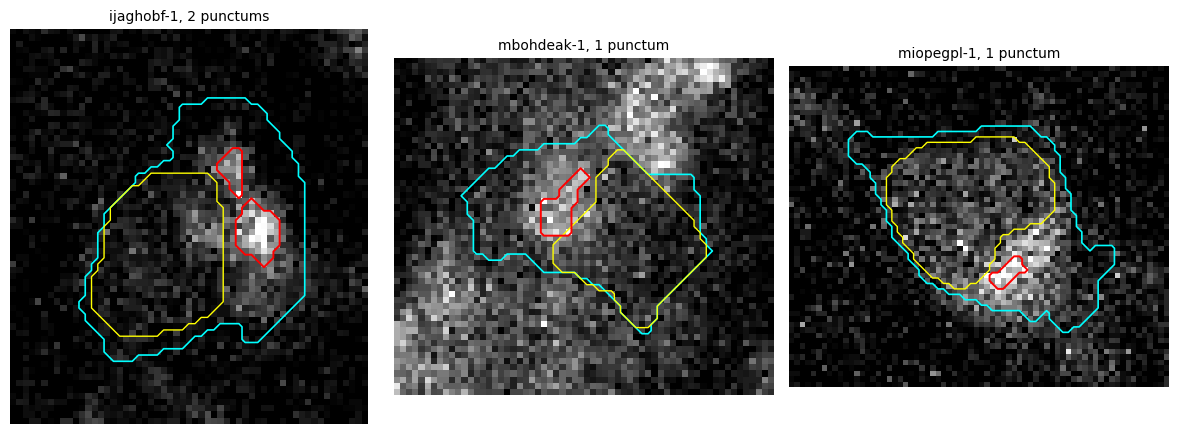

In [6]:
examples = [("ijaghobf-1", "top_left", 38), ("mbohdeak-1", "top_right", 142), ("miopegpl-1", "top_right", 49)]
fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
for (cid, well, fov), ax in zip(examples, axes):
    render_cell(cid, well, fov, ax)
plt.tight_layout()
plt.show()


### Inside vs. outside puncta, by gene
Restricted to cytoplasm (nuclear transcripts excluded on both sides). Two tests have to agree -- a Poisson-binomial test against each cell's own puncta area fraction, and a Cochran-Mantel-Haenszel test against a trimmed reference set of other genes, stratified by cell. Guide-RNA reporter features are dropped before testing.


In [ ]:
# Precomputed by the same pipeline (puncta_pipeline.py + a Poisson-binomial /
# Cochran-Mantel-Haenszel enrichment test, cytoplasm-only, gRNA reporter
# features excluded): is a gene's transcripts enriched inside puncta relative
# to the cytoplasm outside puncta, within the same cells?
res = pd.read_csv("inout_puncta_arsenite_median_no_gRNA.csv")
res[res.significant].sort_values("p_relative")[["feature_name", "direction", "log2_mh_odds_ratio", "p_relative", "fdr_relative"]]


,feature_name,direction,log2_mh_odds_ratio,p_relative,fdr_relative
0,IFITM3,puncta_enriched,0.449731,0.000001,0.000490
1,KIF21A,puncta_enriched,0.201023,0.000012,0.002192
2,EIF5A,puncta_enriched,0.092387,0.000078,0.009325
3,KIT,puncta_enriched,0.613369,0.000609,0.041447
4,PDLIM1,puncta_enriched,0.516944,0.000672,0.041447
5,SSTR2,puncta_enriched,0.216670,0.000810,0.041447
6,GNG5,puncta_enriched,0.130780,0.001012,0.045270


Same result as a volcano plot:

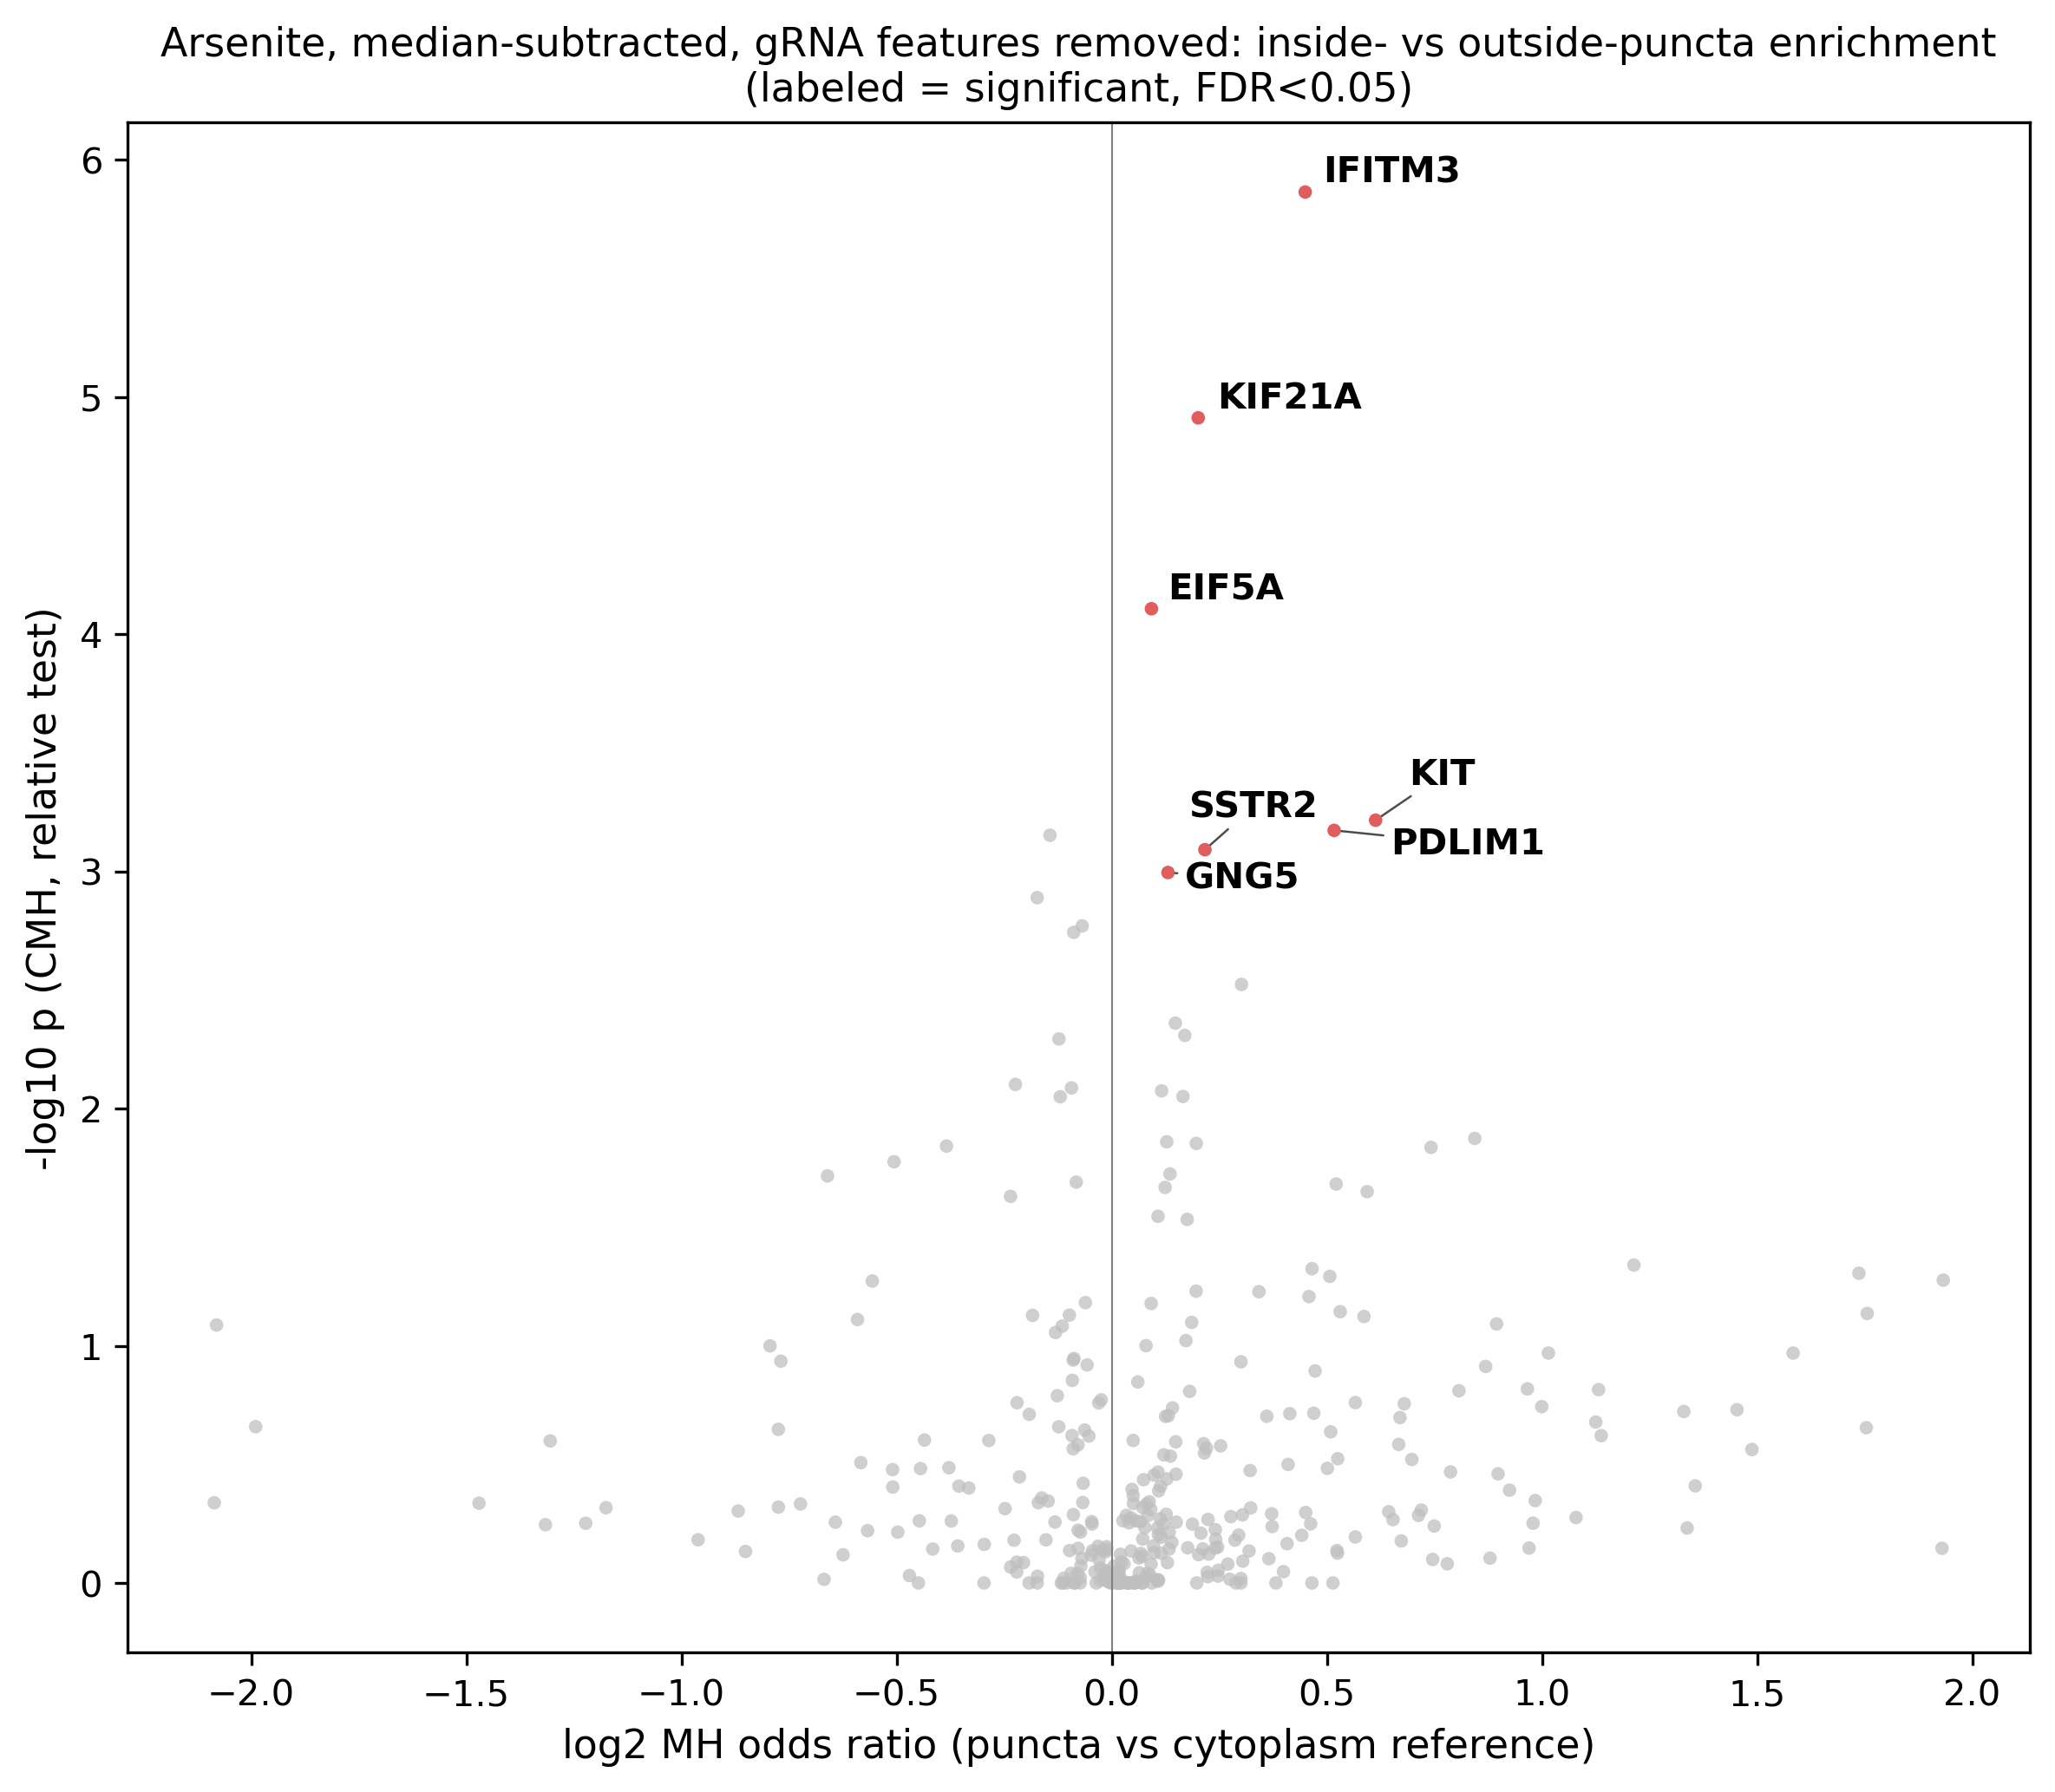

In [ ]:
display(Image(filename="volcano_arsenite_median_no_gRNA.png", width=650))


ijaghobf-1 from above, and eokmgkmn-1, shown with their surrounding field for scale:

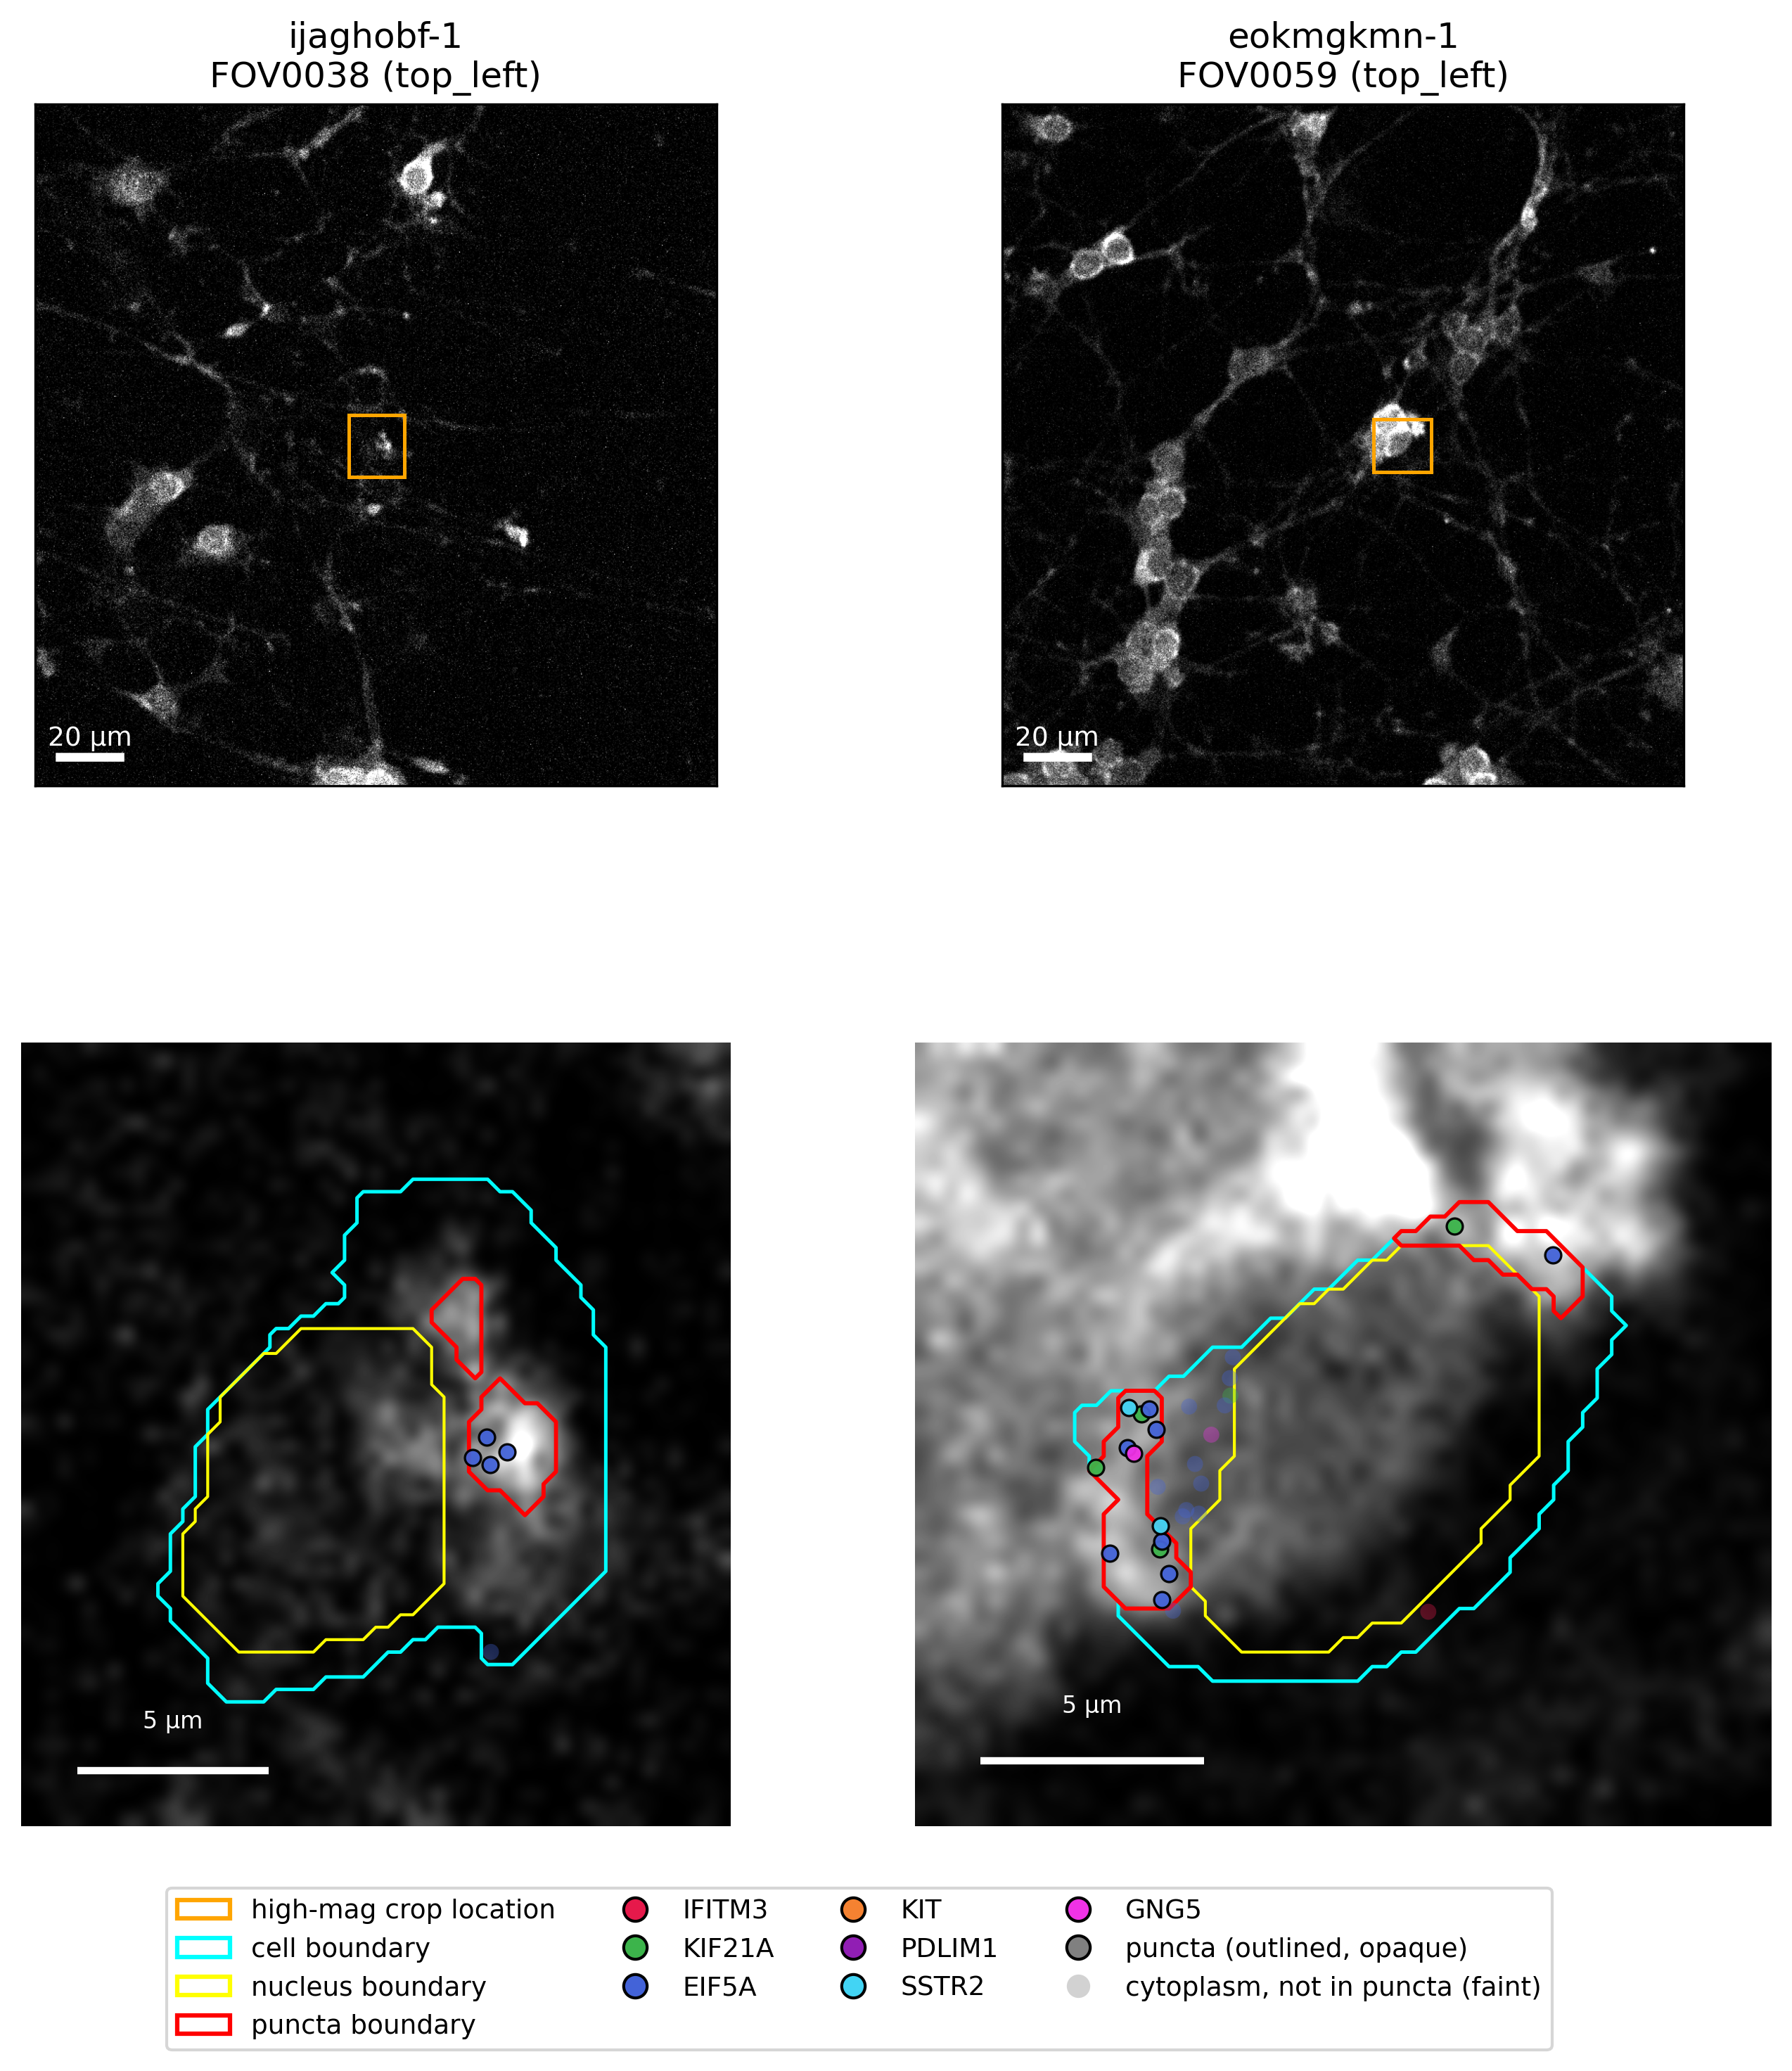

In [ ]:
display(Image(filename="puncta_transcripts_figure2_zoomedout.png", width=950))
